# Lab 2: K-Nearest Neighbors and Radius Neighbors Classification

**Name:** Noel Erkie
**Course:** MSCS 634 – Big Data and Data Mining
**Assignment:** Lab 2 – Classification Using KNN and RNN Algorithms

This lab compares the K-Nearest Neighbors (KNN) and Radius Neighbors (RNN) classifiers on the Wine dataset from
scikit-learn, and examines how the choice of `k` and `radius` affects accuracy.

## Step 1: Load and Prepare the Dataset

In [1]:
# Libraries for data handling, modeling, and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#cfcfcb", "grid.color": "#e6e6e3"})
BLUE, ORANGE = "#2a78d6", "#eb6834"   # blue = KNN, orange = RNN throughout
os.makedirs("figures", exist_ok=True)

# Load the Wine dataset. It ships with scikit-learn, so no download is needed.
wine = load_wine(as_frame=True)
X = wine.data            # 13 chemical measurements per wine
y = wine.target          # class label: 0, 1, or 2 (three wine cultivars)

print("Feature matrix shape:", X.shape)
print("Class names:", [str(c) for c in wine.target_names])
X.head()

Feature matrix shape: (178, 13)
Class names: ['class_0', 'class_1', 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### Feature details

In [2]:
# Data types and missing values
X.info()
print("\nMissing values in the dataset:", X.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: float64(13)
m

In [3]:
# Summary statistics for every feature
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


**Observation:** the dataset is clean (178 samples, 13 numeric features, no missing values), but the features are on
very different scales. `proline` ranges from 278 to 1,680 and `magnesium` from 70 to 162, while most other features
stay below 15. Because KNN and RNN measure Euclidean distance, `proline` will dominate every distance calculation.
This matters for interpreting the results below.

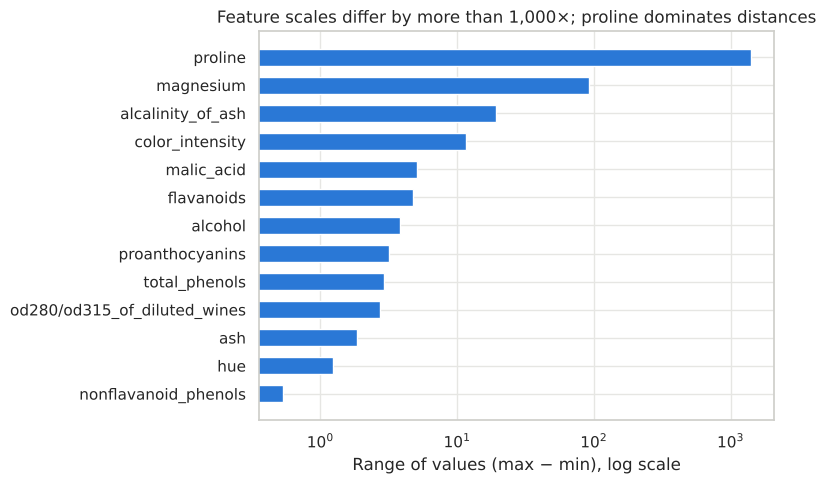

In [4]:
# Feature ranges (max - min) make the scale difference easy to see
ranges = (X.max() - X.min()).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(ranges.index, ranges.values, color=BLUE, height=0.6)
ax.set_xscale("log")
ax.set_xlabel("Range of values (max − min), log scale")
ax.set_title("Feature scales differ by more than 1,000×; proline dominates distances")
plt.tight_layout()
plt.savefig("figures/feature_ranges.png", dpi=120, bbox_inches="tight")
plt.show()

### Class distribution

In [5]:
class_counts = y.value_counts().sort_index()
class_table = pd.DataFrame({
    "Class": [wine.target_names[i] for i in class_counts.index],
    "Count": class_counts.values,
    "Percent": (class_counts.values / len(y) * 100).round(1),
})
class_table

,Class,Count,Percent
0,class_0,59,33.1
1,class_1,71,39.9
2,class_2,48,27.0


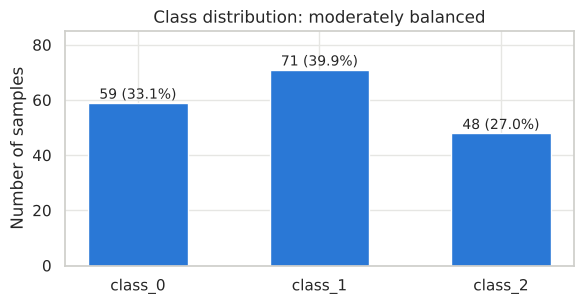

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(class_table["Class"], class_table["Count"], color=BLUE, width=0.55)
for i, (n, p) in enumerate(zip(class_table["Count"], class_table["Percent"])):
    ax.text(i, n + 1.5, f"{n} ({p}%)", ha="center", fontsize=10)
ax.set_ylim(0, 85)
ax.set_ylabel("Number of samples")
ax.set_title("Class distribution: moderately balanced")
plt.tight_layout()
plt.savefig("figures/class_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

**Observation:** the three classes are reasonably balanced (27–40% each), so accuracy is a fair evaluation metric.
A model that always predicts the largest class (class_1) would score about 40%, which is the baseline to beat.

### Train/test split (80% / 20%)

In [7]:
# stratify=y keeps the class proportions the same in both sets.
# random_state=42 makes the split reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape, "| Testing set:", X_test.shape)
print("Training class counts:", np.bincount(y_train))
print("Testing class counts: ", np.bincount(y_test))

Training set: (142, 13) | Testing set: (36, 13)
Training class counts: [47 57 38]
Testing class counts:  [12 14 10]


The test set has 36 samples, so **each misclassified wine lowers accuracy by about 2.8 percentage points**. Small
differences between parameter values should be read with that in mind.

## Step 2: K-Nearest Neighbors (KNN)

KNN classifies a test point by a majority vote of the **k closest** training points. The models are trained on the
original (unscaled) features, as the lab specifies.

In [8]:
k_values = [1, 5, 11, 15, 21]
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)     # default: Euclidean distance, equal-weight vote
    knn.fit(X_train, y_train)                     # train on the training set
    y_pred = knn.predict(X_test)                  # evaluate on the test set
    acc = accuracy_score(y_test, y_pred)
    knn_results.append({"k": k, "Accuracy": acc, "Correct (of 36)": int((y_pred == y_test).sum())})

knn_df = pd.DataFrame(knn_results)
knn_df["Accuracy (%)"] = (knn_df["Accuracy"] * 100).round(2)
knn_df

,k,Accuracy,Correct (of 36),Accuracy (%)
0,1,0.777778,28,77.78
1,5,0.805556,29,80.56
2,11,0.805556,29,80.56
3,15,0.805556,29,80.56
4,21,0.805556,29,80.56


## Step 3: Radius Neighbors (RNN)

RNN classifies a test point by a majority vote of **all training points within a fixed radius**, so the number of
voting neighbors changes from point to point.

`outlier_label="most_frequent"` is set as a safeguard: if a test point had no training points inside the radius, it
would receive the most common training class instead of raising an error. The neighbor counts below show this was
never needed for these radii.

In [9]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_results = []

for r in radius_values:
    rnn = RadiusNeighborsClassifier(radius=r, outlier_label="most_frequent")
    rnn.fit(X_train, y_train)
    y_pred = rnn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    # How many training points fall inside the radius for each test point?
    neighbors = rnn.radius_neighbors(X_test, return_distance=False)
    counts = [len(n) for n in neighbors]

    rnn_results.append({
        "Radius": r,
        "Accuracy": acc,
        "Correct (of 36)": int((y_pred == y_test).sum()),
        "Min neighbors": min(counts),
        "Avg neighbors": round(np.mean(counts), 1),
        "Avg % of training set": round(np.mean(counts) / len(X_train) * 100, 1),
    })

rnn_df = pd.DataFrame(rnn_results)
rnn_df["Accuracy (%)"] = (rnn_df["Accuracy"] * 100).round(2)
rnn_df

,Radius,Accuracy,Correct (of 36),Min neighbors,Avg neighbors,Avg % of training set,Accuracy (%)
0,350,0.722222,26,4,80.5,56.7,72.22
1,400,0.694444,25,9,87.9,61.9,69.44
2,450,0.694444,25,14,94.8,66.8,69.44
3,500,0.694444,25,17,100.1,70.5,69.44
4,550,0.666667,24,19,106.0,74.6,66.67
5,600,0.666667,24,23,111.0,78.1,66.67


**Observation:** these radii are very large relative to most features. At radius 350, an average test point already
has about 80 of the 142 training points (57%) inside its radius; at 600 it is about 111 (78%). Each prediction becomes
a vote among most of the training set, so it moves toward the overall majority class instead of reflecting the local
neighborhood.

## Step 4: Visualize and Compare Results

### KNN accuracy vs. k

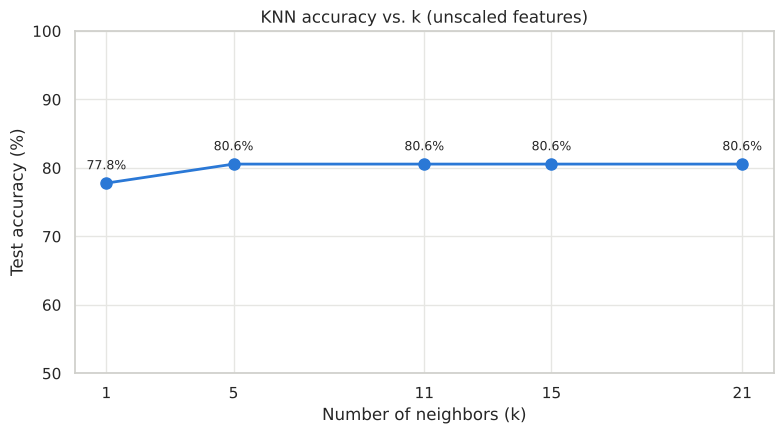

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(knn_df["k"], knn_df["Accuracy (%)"], marker="o", markersize=8, linewidth=2, color=BLUE)
for k, a in zip(knn_df["k"], knn_df["Accuracy (%)"]):
    ax.annotate(f"{a:.1f}%", (k, a), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
ax.set_xticks(k_values)
ax.set_ylim(50, 100)
ax.set_xlabel("Number of neighbors (k)")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("KNN accuracy vs. k (unscaled features)")
plt.tight_layout()
plt.savefig("figures/knn_accuracy.png", dpi=120, bbox_inches="tight")
plt.show()

**KNN trend:** accuracy is lowest at **k = 1 (77.8%)** and rises to **80.6% at k = 5**, then stays flat through k = 21.
With k = 1 the model copies the label of a single nearest point, so it is sensitive to noise and overfits. Larger k
averages over more neighbors and smooths out that noise. The difference is one extra test sample classified correctly.

### RNN accuracy vs. radius

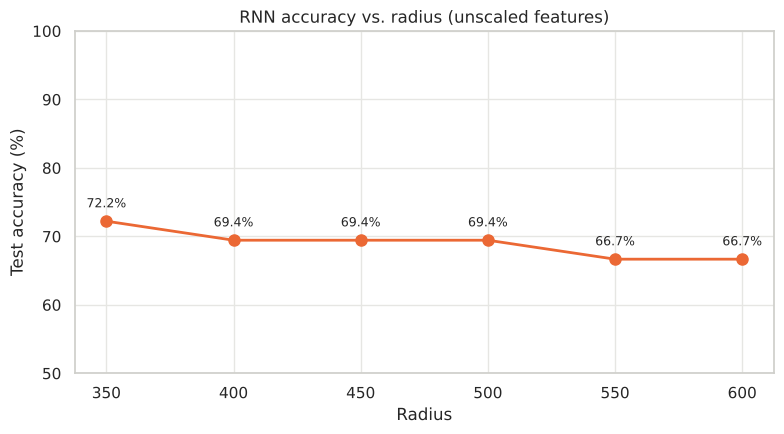

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(rnn_df["Radius"], rnn_df["Accuracy (%)"], marker="o", markersize=8, linewidth=2, color=ORANGE)
for r, a in zip(rnn_df["Radius"], rnn_df["Accuracy (%)"]):
    ax.annotate(f"{a:.1f}%", (r, a), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
ax.set_xticks(radius_values)
ax.set_ylim(50, 100)
ax.set_xlabel("Radius")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("RNN accuracy vs. radius (unscaled features)")
plt.tight_layout()
plt.savefig("figures/rnn_accuracy.png", dpi=120, bbox_inches="tight")
plt.show()

**RNN trend:** accuracy is highest at the **smallest radius, 350 (72.2%)**, and falls as the radius grows, to **66.7% at
550 and 600**. A larger radius pulls in more distant points from other classes, so predictions drift toward the most
common class. The best radius in this range is the smallest one, which suggests an even smaller radius might do better.

### Side-by-side comparison

In [12]:
summary = pd.DataFrame({
    "Model": ["KNN", "RNN"],
    "Parameter range": ["k = 1 to 21", "radius = 350 to 600"],
    "Best accuracy (%)": [knn_df["Accuracy (%)"].max(), rnn_df["Accuracy (%)"].max()],
    "Best parameter": [
        ", ".join(str(k) for k in knn_df.loc[knn_df["Accuracy"] == knn_df["Accuracy"].max(), "k"]),
        ", ".join(str(r) for r in rnn_df.loc[rnn_df["Accuracy"] == rnn_df["Accuracy"].max(), "Radius"]),
    ],
    "Worst accuracy (%)": [knn_df["Accuracy (%)"].min(), rnn_df["Accuracy (%)"].min()],
})
summary

,Model,Parameter range,Best accuracy (%),Best parameter,Worst accuracy (%)
0,KNN,k = 1 to 21,80.56,"5, 11, 15, 21",77.78
1,RNN,radius = 350 to 600,72.22,350,66.67


### Supplementary check: the effect of feature scaling

The lab asks for models on the original features, and the results above use them. Because the scale imbalance stood
out during exploration, this extra check repeats KNN after **standardizing** each feature to mean 0 and standard
deviation 1. The scaler is fit on the training set only, so no information from the test set leaks into training.

In [13]:
scaler = StandardScaler().fit(X_train)          # learn mean/std from training data only
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

scaled_acc = []
for k in k_values:
    knn_s = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    scaled_acc.append(round(accuracy_score(y_test, knn_s.predict(X_test_s)) * 100, 2))

scaling_df = pd.DataFrame({"k": k_values,
                           "Unscaled accuracy (%)": knn_df["Accuracy (%)"],
                           "Scaled accuracy (%)": scaled_acc})
scaling_df

,k,Unscaled accuracy (%),Scaled accuracy (%)
0,1,77.78,97.22
1,5,80.56,97.22
2,11,80.56,100.00
3,15,80.56,100.00
4,21,80.56,100.00


**Observation:** with standardized features, KNN accuracy jumps from about 78–81% to **97–100%**. The low accuracy
in Steps 2 and 3 comes mainly from the feature scales, not from the algorithms. On raw data the "nearest" wines are
mostly the ones with a similar `proline` value, and the other 12 chemical measurements barely count.

The radii in Step 3 (350–600) only make sense on the unscaled data. After standardization, typical distances
between points are only about 3–7 units, so a useful radius would be in the single digits.

## Comparison and Discussion

**Performance:** on this dataset, KNN beat RNN for every parameter tested. KNN's best was 80.6% (k = 5 to 21), and
RNN's best was 72.2% (radius = 350). Both are well above the 40% baseline of always guessing the largest class.

**Why KNN did better here:**

- KNN always uses a fixed, small number of neighbors, so each vote stays local.
- With radii of 350–600, RNN included 57–78% of the whole training set in each vote. That washes out local structure
  and pushes predictions toward the majority class.
- RNN's accuracy fell as the radius grew, while KNN stayed stable from k = 5 to 21. KNN was less sensitive to its
  parameter over the ranges tested.

**When KNN is preferable:**

- When data density varies across the feature space. KNN always finds k neighbors, even in sparse regions.
- When distances are hard to interpret, for example on unscaled data, since choosing k does not require knowing
  what a "close" distance is.
- As a general default: it is simple to tune and, as shown here, robust across a wide range of k.

**When RNN is preferable:**

- When the data is scaled and fairly evenly dense, so a single radius means the same thing everywhere.
- When "similar" has a natural distance threshold, for example sensor readings within a known tolerance.
- When it is useful to detect points that have **no** neighbors within the radius. RNN can flag them as outliers
  (with `outlier_label`) instead of forcing a prediction from far-away points, which KNN cannot do.

**Main lesson:** for distance-based classifiers, **feature scaling matters more than the choice of k or radius.**
The parameter changes in this lab moved accuracy by about 3–6 percentage points, while standardizing the features
moved KNN accuracy by about 20.